# Data cleaning

## Step 1 — Open the training files separately

The training folder currently contains **32 Parquet files**. This section opens each file separately, lists its full row/column counts, and loads the base table into pandas.

The larger history files cannot all fit in this laptop's RAM as pandas DataFrames at the same time. On the current files, the fixed-width columns alone would use approximately **28.6 GiB**, before string values, indexes, and temporary copies. Instead, `train_tables` holds one **PyArrow Dataset** per file. A Dataset is a lazy connection to the complete file: it reads rows when requested.

The files stay separate, including numbered partitions. This section does not join, filter, clean, or overwrite the source data.

In [1]:
from pathlib import Path

import pandas as pd
import pyarrow.dataset as ds
import pyarrow.parquet as pq
from IPython.display import display

# Find the project when Jupyter starts in the project or a subfolder.
project_dir = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "data" / "parquet_files" / "train").is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Open Jupyter from the project folder or its notebooks folder."
    )

train_dir = project_dir / "data" / "parquet_files" / "train"
train_files = sorted(train_dir.glob("*.parquet"))
if not train_files:
    raise FileNotFoundError(f"No training Parquet files found in {train_dir}")

print("Training folder:", train_dir)
print("Training files:", len(train_files))

Training folder: d:\Home Credit - Credit Risk Model Stability\data\parquet_files\train
Training files: 32


In [2]:
# Load the feature-definition reference file
feature_definitions_path = project_dir / "data" / "feature_definitions.csv"
feature_definitions_df = pd.read_csv(feature_definitions_path)

print("Feature definitions shape:", feature_definitions_df.shape)
display(feature_definitions_df.head())

Feature definitions shape: (465, 2)


,Variable,Description
0,actualdpd_943P,Days Past Due (DPD) of previous contract (actu...
1,actualdpdtolerance_344P,DPD of client with tolerance.
2,addres_district_368M,District of the person's address.
3,addres_role_871L,Role of person's address.
4,addres_zip_823M,Zip code of the address.


### See every file before reading its rows

Parquet metadata gives the number of rows and columns without loading the entire table. `Size on disk (MiB)` is the compressed file size, not the RAM it would use as a pandas DataFrame. The counts below refer to all rows in each file.

In [3]:
file_details = []
for file_path in train_files:
    metadata = pq.read_metadata(file_path)
    file_details.append({
        "Table name": file_path.stem,
        "Rows": metadata.num_rows,
        "Columns": metadata.num_columns,
        "Size on disk (MiB)": round(file_path.stat().st_size / 1024**2, 2),
    })

train_file_summary_df = pd.DataFrame(file_details)
with pd.option_context("display.max_rows", None):
    display(train_file_summary_df)

print("Total compressed training files (GiB):",
      round(sum(path.stat().st_size for path in train_files) / 1024**3, 3))

,Table name,Rows,Columns,Size on disk (MiB)
0,train_applprev_1_0,3887684,41,102.00
1,train_applprev_1_1,2638295,41,69.49
2,train_applprev_2,14075487,6,27.17
3,train_base,1526659,5,6.72
4,train_credit_bureau_a_1_0,4108212,79,61.86
5,train_credit_bureau_a_1_1,6009192,79,174.80
6,train_credit_bureau_a_1_2,3743810,79,117.78
7,train_credit_bureau_a_1_3,2079323,79,68.45
8,train_credit_bureau_a_2_0,5296031,19,5.52
9,train_credit_bureau_a_2_1,7861809,19,9.54


Total compressed training files (GiB): 1.237


### Open all files as separate tables

Each dictionary key is a file name without `.parquet`. For example:

- `train_tables["train_base"]`
- `train_tables["train_static_0_0"]`
- `train_tables["train_static_0_1"]`
- `train_tables["train_credit_bureau_a_2_5"]`

Each entry refers to its file's complete rows and columns. These entries are **PyArrow Datasets, not pandas DataFrames**. Creating the dictionary does not read all rows into RAM. See the [PyArrow Dataset documentation](https://arrow.apache.org/docs/16.1/python/generated/pyarrow.dataset.Dataset.html).

In [4]:
# One independent Dataset per physical training file; no concatenation or joins.
train_tables = {
    file_path.stem: ds.dataset(file_path, format="parquet")
    for file_path in train_files
}

print(f"Opened {len(train_tables)} separate training tables.")

Opened 32 separate training tables.


### Load the base table into pandas

The base table is small enough to load fully. `train_base_df` contains all rows and all columns from `train_base.parquet`; `.head()` only limits the displayed preview.

The Kaggle training files also contain the weeks reserved for our internal validation and final holdout. This loading section only inspects structure and a small initial preview. For later cleaning decisions and target-based EDA, use training weeks **0–51**; keep the final holdout protected.

In [5]:
train_base_df = train_tables["train_base"].to_table().to_pandas()

print("Base table rows and columns:", train_base_df.shape)
print("Base DataFrame memory (MiB):",
      round(train_base_df.memory_usage(index=True, deep=True).sum() / 1024**2, 2))
display(train_base_df.head())

Base table rows and columns: (1526659, 5)
Base DataFrame memory (MiB): 132.49


,case_id,date_decision,MONTH,WEEK_NUM,target
0,0,2019-01-03,201901,0,0
1,1,2019-01-03,201901,0,0
2,2,2019-01-04,201901,0,0
3,3,2019-01-03,201901,0,0
4,4,2019-01-04,201901,0,1


In [6]:
# Check the data type of every column
base_dtype_df = pd.DataFrame({
    "column": train_base_df.columns,
    "data_type": train_base_df.dtypes.astype(str).values,
})
display(base_dtype_df)

,column,data_type
0,case_id,int64
1,date_decision,object
2,MONTH,int64
3,WEEK_NUM,int64
4,target,int64


In [7]:
# Check whether any case_id appears more than once
case_id_counts = train_base_df["case_id"].value_counts()
duplicate_case_ids = case_id_counts[case_id_counts > 1]

duplicate_summary_df = pd.DataFrame({
    "measure": [
        "Total rows",
        "Unique case_id values",
        "case_id values appearing more than once",
        "Rows belonging to duplicate case_id values",
    ],
    "value": [
        len(train_base_df),
        train_base_df["case_id"].nunique(),
        len(duplicate_case_ids),
        int(train_base_df["case_id"].duplicated(keep=False).sum()),
    ],
})
display(duplicate_summary_df)

if duplicate_case_ids.empty:
    print("Result: no duplicate case_id values found.")
else:
    print("Duplicate case_id values:")
    display(duplicate_case_ids.to_frame(name="occurrences"))

,measure,value
0,Total rows,1526659
1,Unique case_id values,1526659
2,case_id values appearing more than once,0
3,Rows belonging to duplicate case_id values,0


Result: no duplicate case_id values found.


In [8]:
# Check missing case_id values and completely duplicated rows
missing_case_id_count = int(train_base_df["case_id"].isna().sum())
duplicate_full_row_count = int(
    train_base_df.duplicated(keep=False).sum()
)

row_integrity_summary_df = pd.DataFrame({
    "check": [
        "Missing case_id values",
        "Rows in completely duplicated records",
    ],
    "count": [missing_case_id_count, duplicate_full_row_count],
})
display(row_integrity_summary_df)

if missing_case_id_count == 0 and duplicate_full_row_count == 0:
    print("Result: case_id is complete and no completely duplicated rows were found.")
else:
    print("Result: investigate the checks with nonzero counts before cleaning.")

,check,count
0,Missing case_id values,0
1,Rows in completely duplicated records,0


Result: case_id is complete and no completely duplicated rows were found.


In [9]:
# Check missing values in every train_base column
missing_summary_df = pd.DataFrame({
    "column": train_base_df.columns,
    "missing_count": train_base_df.isna().sum().values,
})
missing_summary_df["missing_percent"] = (
    missing_summary_df["missing_count"] / len(train_base_df) * 100
)
missing_summary_df = missing_summary_df.sort_values(
    "missing_count", ascending=False
).reset_index(drop=True)
display(missing_summary_df)

print(f"Total missing values: {int(missing_summary_df['missing_count'].sum()):,}")

,column,missing_count,missing_percent
0,case_id,0,0.0
1,date_decision,0,0.0
2,MONTH,0,0.0
3,WEEK_NUM,0,0.0
4,target,0,0.0


Total missing values: 0


In [10]:
# Check the observed values in the target column
target_value_counts_df = (
    train_base_df["target"]
    .value_counts(dropna=False)
    .rename_axis("target_value")
    .reset_index(name="row_count")
)
display(target_value_counts_df)

valid_target_values = {0, 1}
invalid_target_mask = ~train_base_df["target"].isin(valid_target_values)
invalid_target_count = int(invalid_target_mask.sum())

if invalid_target_count == 0:
    print("Result: every target value is 0 or 1.")
else:
    print(f"Result: {invalid_target_count:,} rows have a target value other than 0 or 1.")
    display(train_base_df.loc[invalid_target_mask, ["case_id", "target"]].head(20))

,target_value,row_count
0,0,1478665
1,1,47994


Result: every target value is 0 or 1.


In [11]:
# Check whether date_decision, MONTH, and WEEK_NUM are consistent
base_decision_dates = pd.to_datetime(
    train_base_df["date_decision"], errors="coerce"
)
invalid_date_count = int(base_decision_dates.isna().sum())

expected_month = (
    base_decision_dates.dt.year * 100
    + base_decision_dates.dt.month
)
month_mismatch_mask = (
    base_decision_dates.notna()
    & expected_month.ne(train_base_df["MONTH"])
)

week_date_audit_df = (
    pd.DataFrame({
        "WEEK_NUM": train_base_df["WEEK_NUM"],
        "date_decision": base_decision_dates,
    })
    .groupby("WEEK_NUM", dropna=False)["date_decision"]
    .agg(first_date="min", last_date="max", application_count="size")
    .reset_index()
    .sort_values("WEEK_NUM")
)
week_order_ok = (
    week_date_audit_df["first_date"].is_monotonic_increasing
    and week_date_audit_df["last_date"].is_monotonic_increasing
)

date_week_summary_df = pd.DataFrame({
    "check": [
        "Invalid decision dates",
        "MONTH/date_decision mismatches",
        "WEEK_NUM dates move forward chronologically",
    ],
    "result": [invalid_date_count, int(month_mismatch_mask.sum()), week_order_ok],
})
display(date_week_summary_df)
display(week_date_audit_df.head(10))

if invalid_date_count == 0 and month_mismatch_mask.sum() == 0 and week_order_ok:
    print("Result: date, MONTH, and WEEK_NUM are structurally consistent.")
else:
    print("Result: investigate the checks marked nonzero or False before splitting.")

,check,result
0,Invalid decision dates,0
1,MONTH/date_decision mismatches,0
2,WEEK_NUM dates move forward chronologically,True


,WEEK_NUM,first_date,last_date,application_count
0,0,2019-01-01,2019-01-07,16735
1,1,2019-01-08,2019-01-14,18841
2,2,2019-01-15,2019-01-21,17476
3,3,2019-01-22,2019-01-28,16108
4,4,2019-01-29,2019-02-04,14309
5,5,2019-02-05,2019-02-11,15335
6,6,2019-02-12,2019-02-18,16385
7,7,2019-02-19,2019-02-25,17238
8,8,2019-02-26,2019-03-04,13076
9,9,2019-03-05,2019-03-11,14716


Result: date, MONTH, and WEEK_NUM are structurally consistent.


In [12]:
# Check WEEK_NUM coverage, decision-date range, and MONTH format
expected_week_values = set(range(0, 92))
observed_week_values = set(train_base_df["WEEK_NUM"].dropna().unique())
missing_expected_weeks = sorted(expected_week_values - observed_week_values)
unexpected_week_values = sorted(observed_week_values - expected_week_values)

decision_date_min = base_decision_dates.min()
decision_date_max = base_decision_dates.max()

month_values = train_base_df["MONTH"]
month_year = month_values // 100
month_number = month_values % 100
invalid_month_mask = (
    month_values.isna()
    | month_year.notna().eq(False)
    | ~month_year.between(1000, 9999)
    | ~month_number.between(1, 12)
)

time_range_summary_df = pd.DataFrame({
    "check": [
        "Minimum WEEK_NUM",
        "Maximum WEEK_NUM",
        "Missing expected weeks from 0 to 91",
        "Unexpected WEEK_NUM values",
        "Minimum decision date",
        "Maximum decision date",
        "Invalid MONTH values",
    ],
    "result": [
        train_base_df["WEEK_NUM"].min(),
        train_base_df["WEEK_NUM"].max(),
        missing_expected_weeks,
        unexpected_week_values,
        decision_date_min,
        decision_date_max,
        int(invalid_month_mask.sum()),
    ],
})
display(time_range_summary_df)

if not missing_expected_weeks and not unexpected_week_values and invalid_month_mask.sum() == 0:
    print("Result: WEEK_NUM and MONTH values are within the expected structure.")
else:
    print("Result: investigate the checks with missing, unexpected, or invalid values.")

,check,result
0,Minimum WEEK_NUM,0
1,Maximum WEEK_NUM,91
2,Missing expected weeks from 0 to 91,[]
3,Unexpected WEEK_NUM values,[]
4,Minimum decision date,2019-01-01 00:00:00
5,Maximum decision date,2020-10-05 00:00:00
6,Invalid MONTH values,0


Result: WEEK_NUM and MONTH values are within the expected structure.


,WEEK_NUM,application_count,default_count,default_rate
0,0,16735,400,0.023902
1,1,18841,472,0.025052
2,2,17476,465,0.026608
3,3,16108,419,0.026012
4,4,14309,404,0.028234
...,...,...,...,...
87,87,17886,329,0.018394
88,88,14234,265,0.018617
89,89,13600,309,0.022721
90,90,12103,330,0.027266


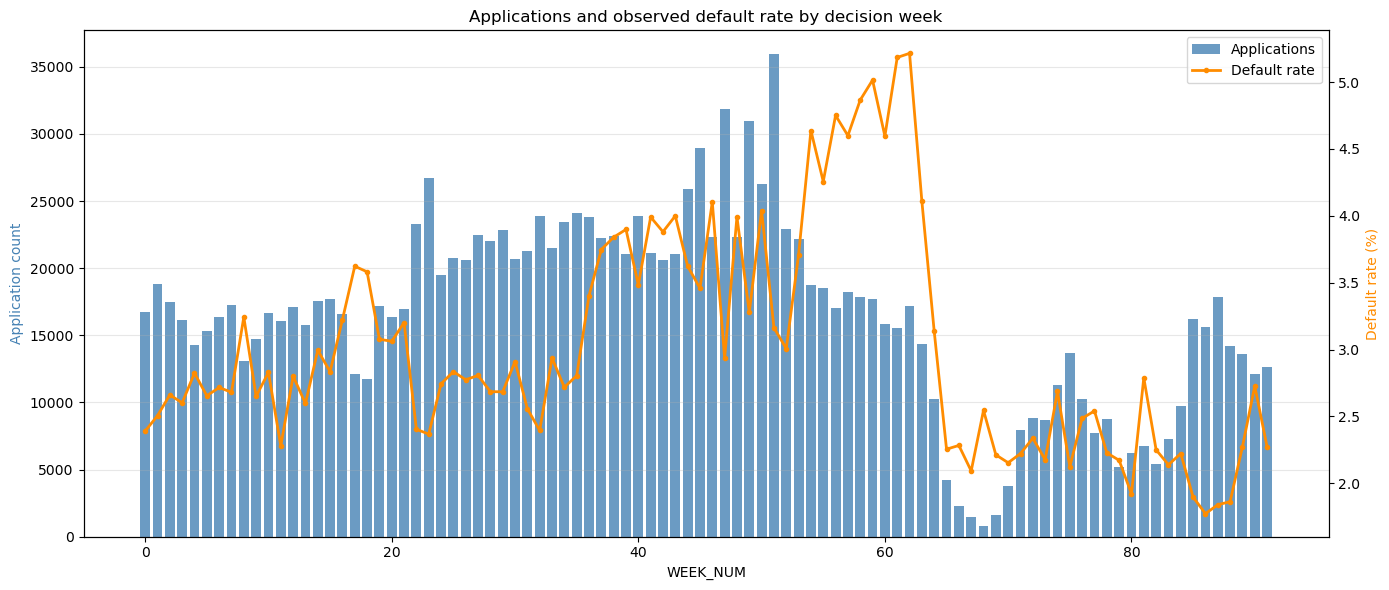

In [13]:
# Summarize applications and observed default rates by week
import matplotlib.pyplot as plt

weekly_target_summary_df = (
    train_base_df.groupby("WEEK_NUM", as_index=False)
    .agg(
        application_count=("case_id", "size"),
        default_count=("target", "sum"),
        default_rate=("target", "mean"),
    )
    .sort_values("WEEK_NUM")
)
display(weekly_target_summary_df)

fig, application_axis = plt.subplots(figsize=(14, 6))
rate_axis = application_axis.twinx()

bars = application_axis.bar(
    weekly_target_summary_df["WEEK_NUM"],
    weekly_target_summary_df["application_count"],
    color="steelblue",
    alpha=0.8,
    label="Applications",
)
line = rate_axis.plot(
    weekly_target_summary_df["WEEK_NUM"],
    weekly_target_summary_df["default_rate"] * 100,
    color="darkorange",
    marker="o",
    markersize=3,
    linewidth=2,
    label="Default rate",
)

application_axis.set_title("Applications and observed default rate by decision week")
application_axis.set_xlabel("WEEK_NUM")
application_axis.set_ylabel("Application count", color="steelblue")
rate_axis.set_ylabel("Default rate (%)", color="darkorange")
application_axis.grid(axis="y", alpha=0.3)

handles = [bars, line[0]]
labels = [handle.get_label() for handle in handles]
application_axis.legend(handles, labels, loc="upper right")
plt.tight_layout()
plt.show()

In [14]:
# Create chronological train, validation, and locked holdout splits
train_df = train_base_df.loc[train_base_df["WEEK_NUM"].between(0, 51)].copy()
validation_df = train_base_df.loc[train_base_df["WEEK_NUM"].between(52, 71)].copy()
test_holdout_df = train_base_df.loc[train_base_df["WEEK_NUM"].between(72, 91)].copy()

split_summary_df = pd.DataFrame({
    "split": ["train", "validation", "locked_holdout"],
    "weeks": ["0-51", "52-71", "72-91"],
    "rows": [len(train_df), len(validation_df), len(test_holdout_df)],
    "default_count": [
        int(train_df["target"].sum()),
        int(validation_df["target"].sum()),
        int(test_holdout_df["target"].sum()),
    ],
})
split_summary_df["default_rate"] = (
    split_summary_df["default_count"] / split_summary_df["rows"]
)
display(split_summary_df)

assert train_df["WEEK_NUM"].max() < validation_df["WEEK_NUM"].min()
assert validation_df["WEEK_NUM"].max() < test_holdout_df["WEEK_NUM"].min()
print("Result: chronological split created successfully.")
print("Keep test_holdout_df untouched until final evaluation.")

,split,weeks,rows,default_count,default_rate
0,train,0-51,1065921,32929,0.030893
1,validation,52-71,248535,10409,0.041881
2,locked_holdout,72-91,212203,4656,0.021941


Result: chronological split created successfully.
Keep test_holdout_df untouched until final evaluation.


In [15]:
# Check repeated applications, split overlap, and weekly target-rate changes
full_case_id_counts = train_base_df["case_id"].value_counts()
repeated_application_ids = full_case_id_counts[full_case_id_counts > 1]

train_ids = set(train_df["case_id"])
validation_ids = set(validation_df["case_id"])
holdout_ids = set(test_holdout_df["case_id"])

split_overlap_summary_df = pd.DataFrame({
    "comparison": [
        "Train vs validation",
        "Train vs locked holdout",
        "Validation vs locked holdout",
    ],
    "overlapping_case_id_count": [
        len(train_ids & validation_ids),
        len(train_ids & holdout_ids),
        len(validation_ids & holdout_ids),
    ],
})

weekly_rate_comparison_df = (
    train_base_df.groupby("WEEK_NUM", as_index=False)
    .agg(
        application_count=("case_id", "size"),
        default_count=("target", "sum"),
        default_rate=("target", "mean"),
    )
    .sort_values("WEEK_NUM")
)

audit_summary_df = pd.DataFrame({
    "check": [
        "Repeated case_id values in full base table",
        "Rows belonging to repeated case_id values",
    ],
    "count": [
        len(repeated_application_ids),
        int(train_base_df["case_id"].duplicated(keep=False).sum()),
    ],
})
display(audit_summary_df)
display(split_overlap_summary_df)
display(weekly_rate_comparison_df)

lowest_week = weekly_rate_comparison_df.loc[weekly_rate_comparison_df["default_rate"].idxmin()]
highest_week = weekly_rate_comparison_df.loc[weekly_rate_comparison_df["default_rate"].idxmax()]
print(
    f"Lowest weekly default rate: week {int(lowest_week['WEEK_NUM'])} "
    f"({lowest_week['default_rate']:.2%})"
)
print(
    f"Highest weekly default rate: week {int(highest_week['WEEK_NUM'])} "
    f"({highest_week['default_rate']:.2%})"
)

,check,count
0,Repeated case_id values in full base table,0
1,Rows belonging to repeated case_id values,0


,comparison,overlapping_case_id_count
0,Train vs validation,0
1,Train vs locked holdout,0
2,Validation vs locked holdout,0


,WEEK_NUM,application_count,default_count,default_rate
0,0,16735,400,0.023902
1,1,18841,472,0.025052
2,2,17476,465,0.026608
3,3,16108,419,0.026012
4,4,14309,404,0.028234
...,...,...,...,...
87,87,17886,329,0.018394
88,88,14234,265,0.018617
89,89,13600,309,0.022721
90,90,12103,330,0.027266


Lowest weekly default rate: week 86 (1.77%)
Highest weekly default rate: week 62 (5.21%)


In [16]:
# Load, combine, and inspect the complete train_static_0 table
train_static_0_0_df = train_tables["train_static_0_0"].to_table().to_pandas()
train_static_0_1_df = train_tables["train_static_0_1"].to_table().to_pandas()

if list(train_static_0_0_df.columns) != list(train_static_0_1_df.columns):
    raise ValueError("The train_static_0 partitions do not have matching columns.")

train_static_0_df = pd.concat(
    [train_static_0_0_df, train_static_0_1_df],
    ignore_index=True,
)

print("train_static_0_0 shape:", train_static_0_0_df.shape)
print("train_static_0_1 shape:", train_static_0_1_df.shape)
print("Combined train_static_0 shape:", train_static_0_df.shape)

static_0_dtype_df = pd.DataFrame({
    "column": train_static_0_df.columns,
    "data_type": train_static_0_df.dtypes.astype(str).values,
})
print("Data types of all train_static_0 columns:")
with pd.option_context("display.max_rows", None):
    display(static_0_dtype_df)

train_static_0_0 shape: (1003757, 168)
train_static_0_1 shape: (522902, 168)
Combined train_static_0 shape: (1526659, 168)
Data types of all train_static_0 columns:


,column,data_type
0,case_id,int64
1,actualdpdtolerance_344P,float64
2,amtinstpaidbefduel24m_4187115A,float64
3,annuity_780A,float64
4,annuitynextmonth_57A,float64
5,applicationcnt_361L,float64
6,applications30d_658L,float64
7,applicationscnt_1086L,float64
8,applicationscnt_464L,float64
9,applicationscnt_629L,float64


In [17]:
# Count and group train_static_0 columns by data type, meaning, and example value
static_dtype_counts_df = (
    train_static_0_df.dtypes.astype(str)
    .value_counts()
    .rename_axis("data_type")
    .reset_index(name="column_count")
)
display(static_dtype_counts_df)

static_example_values = {
    column: (
        train_static_0_df[column].dropna().iloc[0]
        if train_static_0_df[column].notna().any()
        else pd.NA
    )
    for column in train_static_0_df.columns
}

static_column_definitions_df = pd.DataFrame({
    "column": train_static_0_df.columns,
    "data_type": train_static_0_df.dtypes.astype(str).values,
    "example_value": [
        static_example_values[column] for column in train_static_0_df.columns
    ],
}).merge(
    feature_definitions_df.rename(
        columns={"Variable": "column", "Description": "meaning"}
    ),
    on="column",
    how="left",
    validate="one_to_one",
)

for data_type in static_column_definitions_df["data_type"].unique():
    grouped_columns_df = static_column_definitions_df.loc[
        static_column_definitions_df["data_type"].eq(data_type),
        ["column", "data_type", "meaning", "example_value"],
    ].reset_index(drop=True)
    print(f"{data_type} columns ({len(grouped_columns_df)}):")
    display(grouped_columns_df)

unmatched_definition_count = int(static_column_definitions_df["meaning"].isna().sum())
print(f"Static columns without a feature definition: {unmatched_definition_count}")

,data_type,column_count
0,float64,128
1,object,38
2,int64,1
3,bool,1


int64 columns (1):


,column,data_type,meaning,example_value
0,case_id,int64,NaN,0


float64 columns (128):


,column,data_type,meaning,example_value
0,actualdpdtolerance_344P,float64,DPD of client with tolerance.,0.0
1,amtinstpaidbefduel24m_4187115A,float64,Number of instalments paid before due date in ...,7374.0
2,annuity_780A,float64,Monthly annuity amount.,1917.6
3,annuitynextmonth_57A,float64,Next month's amount of annuity.,0.0
4,applicationcnt_361L,float64,Number of applications associated with the sam...,0.0
...,...,...,...,...
123,sumoutstandtotal_3546847A,float64,Sum of total outstanding amount.,0.0
124,sumoutstandtotalest_4493215A,float64,Sum of total outstanding amount.,0.0
125,totaldebt_9A,float64,Total amount of debt.,0.0
126,totalsettled_863A,float64,Sum of all payments made by the client.,0.0


object columns (38):


,column,data_type,meaning,example_value
0,bankacctype_710L,object,Type of applicant's bank account.,CA
1,cardtype_51L,object,Type of credit card.,INSTANT
2,credtype_322L,object,Type of credit.,CAL
3,datefirstoffer_1144D,object,Date of first customer relationship management...,2019-01-07
4,datelastinstal40dpd_247D,object,Date of last instalment that was more than 40 ...,2016-02-15
5,datelastunpaid_3546854D,object,Date of the last unpaid instalment.,2018-12-31
6,disbursementtype_67L,object,Type of disbursement.,GBA
7,dtlastpmtallstes_4499206D,object,Date of last payment made by the applicant.,2019-08-29
8,equalitydataagreement_891L,object,Flag indicating sudden changes in client's soc...,True
9,equalityempfrom_62L,object,Flag indicating a sudden change in the client'...,True


bool columns (1):


,column,data_type,meaning,example_value
0,isbidproduct_1095L,bool,Flag indicating if the product is a cross-sell.,False


Static columns without a feature definition: 1


In [18]:
# Inspect every category in every object-type static column
object_columns = train_static_0_df.select_dtypes(include=["object"]).columns.tolist()
print(f"Object columns found: {len(object_columns)}")

object_category_count_df = pd.DataFrame({
    "column": object_columns,
    "category_count": [
        train_static_0_df[column].nunique(dropna=False)
        for column in object_columns
    ],
})
display(object_category_count_df)

object_category_tables = {}
for column in object_columns:
    category_rows_df = train_static_0_df[[column, "case_id"]].rename(
        columns={column: "category"}
    )
    category_rows_df["category"] = category_rows_df["category"].astype("object")
    category_rows_df["category"] = category_rows_df["category"].where(
        category_rows_df["category"].notna(),
        "<MISSING>",
    )

    category_summary_df = (
        category_rows_df.groupby("category", dropna=False, sort=False)
        .agg(
            category_count=("category", "size"),
            example_case_id=("case_id", "first"),
        )
        .reset_index()
        .sort_values("category_count", ascending=False)
        .reset_index(drop=True)
    )
    object_category_tables[column] = category_summary_df

    print(f"{column}: {len(category_summary_df)} categories")
    display(category_summary_df)


Object columns found: 38


,column,category_count
0,bankacctype_710L,2
1,cardtype_51L,3
2,credtype_322L,4
3,datefirstoffer_1144D,1405
4,datelastinstal40dpd_247D,5176
5,datelastunpaid_3546854D,5232
6,disbursementtype_67L,4
7,dtlastpmtallstes_4499206D,4465
8,equalitydataagreement_891L,3
9,equalityempfrom_62L,3


bankacctype_710L: 2 categories


,category,category_count,example_case_id
0,<MISSING>,1109629,0
1,CA,417030,6


cardtype_51L: 3 categories


,category,category_count,example_case_id
0,<MISSING>,1334968,0
1,INSTANT,189370,5
2,PERSONALIZED,2321,523


... (68 outputs left out)

typesuite_864L: 2 categories


,category,category_count,example_case_id
0,<MISSING>,1121505,0
1,AL,405154,2


validfrom_1069D: 619 categories


,category,category_count,example_case_id
0,<MISSING>,1374886,0
1,2019-06-18,15175,133383
2,2019-10-16,9424,163764
3,2019-02-11,9114,107818
4,2019-10-02,4488,160246
...,...,...,...
614,2020-04-21,1,2681158
615,2018-10-03,1,2530486
616,2018-10-02,1,2530963
617,2018-09-25,1,2531131


In [19]:
# Check missing values in every object-type static column
object_columns = train_static_0_df.select_dtypes(include=["object"]).columns.tolist()

object_missing_summary_df = pd.DataFrame({
    "column": object_columns,
    "missing_count": [
        int(train_static_0_df[column].isna().sum())
        for column in object_columns
    ],
})
object_missing_summary_df["missing_percent"] = (
    object_missing_summary_df["missing_count"]
    / len(train_static_0_df)
    * 100
)
object_missing_summary_df = object_missing_summary_df.sort_values(
    "missing_count", ascending=False
).reset_index(drop=True)

display(object_missing_summary_df)


,column,missing_count,missing_percent
0,lastrepayingdate_696D,1524282,99.844301
1,payvacationpostpone_4187118D,1517330,99.388927
2,isbidproductrequest_292L,1514201,99.183970
3,equalityempfrom_62L,1488847,97.523219
4,equalitydataagreement_891L,1448632,94.889035
5,datelastinstal40dpd_247D,1392841,91.234585
6,validfrom_1069D,1374886,90.058487
7,cardtype_51L,1334968,87.443758
8,isdebitcard_729L,1334357,87.403736
9,typesuite_864L,1121505,73.461395


In [20]:
# Filter only object-type static columns using missingness and category rules
missing_threshold = 50.0
category_threshold = 10

static_filter_summary_df = pd.DataFrame({
    "column": train_static_0_df.columns,
    "data_type": train_static_0_df.dtypes.astype(str).values,
    "missing_percent": [
        train_static_0_df[column].isna().mean() * 100
        for column in train_static_0_df.columns
    ],
    "category_count": [
        train_static_0_df[column].nunique(dropna=True)
        if train_static_0_df[column].dtype == "object"
        else pd.NA
        for column in train_static_0_df.columns
    ],
})

is_object_column = static_filter_summary_df["data_type"].eq("object")
static_filter_summary_df["remove_missing"] = (
    is_object_column
    & static_filter_summary_df["missing_percent"].gt(missing_threshold)
)
static_filter_summary_df["remove_many_categories"] = (
    is_object_column
    & static_filter_summary_df["category_count"].gt(category_threshold)
)
static_filter_summary_df["remove_column"] = (
    static_filter_summary_df["remove_missing"]
    | static_filter_summary_df["remove_many_categories"]
)

columns_to_remove = static_filter_summary_df.loc[
    static_filter_summary_df["remove_column"], "column"
].tolist()
columns_to_keep = static_filter_summary_df.loc[
    ~static_filter_summary_df["remove_column"], "column"
].tolist()

train_static_0_filtered_df = train_static_0_df.loc[:, columns_to_keep].copy()

print(f"Original static columns: {train_static_0_df.shape[1]}")
print(f"Object columns considered: {int(is_object_column.sum())}")
print(f"Removed object columns: {len(columns_to_remove)}")
print(f"Filtered static columns: {train_static_0_filtered_df.shape[1]}")
print(f"Rows preserved: {train_static_0_filtered_df.shape[0]:,}")

print("Removed object-column details:")
display(
    static_filter_summary_df.loc[
        static_filter_summary_df["remove_column"],
        [
            "column",
            "data_type",
            "missing_percent",
            "category_count",
            "remove_missing",
            "remove_many_categories",
        ],
    ].reset_index(drop=True)
)

print("Filtered DataFrame preview:")
display(train_static_0_filtered_df.head())


Original static columns: 168
Object columns considered: 38
Removed object columns: 31
Filtered static columns: 137
Rows preserved: 1,526,659
Removed object-column details:


,column,data_type,missing_percent,category_count,remove_missing,remove_many_categories
0,bankacctype_710L,object,72.683487,1,True,False
1,cardtype_51L,object,87.443758,2,True,False
2,datefirstoffer_1144D,object,54.611737,1404,True,True
3,datelastinstal40dpd_247D,object,91.234585,5175,True,True
4,datelastunpaid_3546854D,object,58.143895,5231,True,True
5,dtlastpmtallstes_4499206D,object,64.003749,4464,True,True
6,equalitydataagreement_891L,object,94.889035,2,True,False
7,equalityempfrom_62L,object,97.523219,2,True,False
8,firstclxcampaign_1125D,object,56.280676,1248,True,True
9,firstdatedue_489D,object,31.578958,5210,False,True


Filtered DataFrame preview:


,case_id,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,...,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,sumoutstandtotalest_4493215A,totaldebt_9A,totalsettled_863A,totinstallast1m_4525188A,twobodfilling_608L
0,0,NaN,NaN,1917.6,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,BO
1,1,NaN,NaN,3134.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,BO
2,2,NaN,NaN,4937.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,BO
3,3,NaN,NaN,4643.6,0.0,0.0,1.0,0.0,2.0,0.0,...,NaN,NaN,1.0,1.0,NaN,NaN,0.0,0.0,NaN,BO
4,4,NaN,NaN,3390.2,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,BO


In [21]:
# Check missing values in every boolean-type static column
boolean_columns = train_static_0_df.select_dtypes(include=["bool"]).columns.tolist()

if not boolean_columns:
    print("No boolean columns found.")
else:
    boolean_missing_summary_df = pd.DataFrame({
        "column": boolean_columns,
        "missing_count": [
            int(train_static_0_df[column].isna().sum())
            for column in boolean_columns
        ],
    })
    boolean_missing_summary_df["missing_percent"] = (
        boolean_missing_summary_df["missing_count"]
        / len(train_static_0_df)
        * 100
    )
    display(boolean_missing_summary_df)


,column,missing_count,missing_percent
0,isbidproduct_1095L,0,0.0


In [22]:
# Check missing values in every float64 static column
float_columns = train_static_0_df.select_dtypes(include=["float64"]).columns.tolist()

float_missing_summary_df = pd.DataFrame({
    "column": float_columns,
    "missing_count": [
        int(train_static_0_df[column].isna().sum())
        for column in float_columns
    ],
})
float_missing_summary_df["missing_percent"] = (
    float_missing_summary_df["missing_count"]
    / len(train_static_0_df)
    * 100
)
float_missing_summary_df = float_missing_summary_df.sort_values(
    "missing_count", ascending=False
).reset_index(drop=True)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(float_missing_summary_df)


,column,missing_count,missing_percent
0,clientscnt_136L,1526242,99.972685
1,lastotherinc_902A,1523603,99.799824
2,lastotherlnsexpense_631A,1523601,99.799693
3,interestrategrace_34L,1505776,98.632111
4,lastdependentsnum_448L,1497142,98.066562
5,maxannuity_4075009A,1450726,95.026198
6,avglnamtstart24m_4525187A,1364150,89.355252
7,inittransactionamount_650A,1334357,87.403736
8,totinstallast1m_4525188A,1174211,76.913771
9,maxpmtlast3m_4525190A,1129330,73.973952


In [23]:
# Check float-column missing percentages for every WEEK_NUM
float_columns = train_static_0_df.select_dtypes(include=["float64"]).columns.tolist()

# WEEK_NUM is stored in train_base_df, so attach it by case_id first.
static_float_with_week_df = train_static_0_df[
    ["case_id", *float_columns]
].merge(
    train_base_df[["case_id", "WEEK_NUM"]],
    on="case_id",
    how="left",
    validate="one_to_one",
)

weekly_float_missing_percentage_df = (
    static_float_with_week_df.groupby("WEEK_NUM")[float_columns]
    .agg(lambda values: values.isna().mean() * 100)
    .reset_index()
)

print(
    "Each value below is the percentage of missing values for that feature "
    "within the corresponding week."
)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(weekly_float_missing_percentage_df.round(2))


Each value below is the percentage of missing values for that feature within the corresponding week.


,WEEK_NUM,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,applicationscnt_867L,avgdbddpdlast24m_3658932P,avgdbddpdlast3m_4187120P,avgdbdtollast24m_4525197P,avgdpdtolclosure24_3658938P,avginstallast24m_3658937A,avglnamtstart24m_4525187A,avgmaxdpdlast9m_3716943P,avgoutstandbalancel6m_4187114A,avgpmtlast12m_4525200A,clientscnt12m_3712952L,clientscnt3m_3712950L,clientscnt6m_3712949L,clientscnt_100L,clientscnt_1022L,clientscnt_1071L,clientscnt_1130L,clientscnt_136L,clientscnt_157L,clientscnt_257L,clientscnt_304L,clientscnt_360L,clientscnt_493L,clientscnt_533L,clientscnt_887L,clientscnt_946L,cntincpaycont9m_3716944L,cntpmts24_3658933L,commnoinclast6m_3546845L,credamount_770A,currdebt_22A,currdebtcredtyperange_828A,daysoverduetolerancedd_3976961L,deferredmnthsnum_166L,disbursedcredamount_1113A,downpmt_116A,eir_270L,homephncnt_628L,inittransactionamount_650A,interestrate_311L,interestrategrace_34L,lastapprcredamount_781A,lastdependentsnum_448L,lastotherinc_902A,lastotherlnsexpense_631A,lastrejectcredamount_222A,maininc_215A,mastercontrelectronic_519L,mastercontrexist_109L,maxannuity_159A,maxannuity_4075009A,maxdbddpdlast1m_3658939P,maxdbddpdtollast12m_3658940P,maxdbddpdtollast6m_4187119P,maxdebt4_972A,maxdpdfrom6mto36m_3546853P,maxdpdinstlnum_3546846P,maxdpdlast12m_727P,maxdpdlast24m_143P,maxdpdlast3m_392P,maxdpdlast6m_474P,maxdpdlast9m_1059P,maxdpdtolerance_374P,maxinstallast24m_3658928A,maxlnamtstart6m_4525199A,maxoutstandbalancel12m_4187113A,maxpmtlast3m_4525190A,mindbddpdlast24m_3658935P,mindbdtollast24m_4525191P,mobilephncnt_593L,monthsannuity_845L,numactivecreds_622L,numactivecredschannel_414L,numactiverelcontr_750L,numcontrs3months_479L,numincomingpmts_3546848L,numinstlallpaidearly3d_817L,numinstls_657L,numinstlsallpaid_934L,numinstlswithdpd10_728L,numinstlswithdpd5_4187116L,numinstlswithoutdpd_562L,numinstmatpaidtearly2d_4499204L,numinstpaid_4499208L,numinstpaidearly3d_3546850L,numinstpaidearly3dest_4493216L,numinstpaidearly5d_1087L,numinstpaidearly5dest_4493211L,numinstpaidearly5dobd_4499205L,numinstpaidearly_338L,numinstpaidearlyest_4493214L,numinstpaidlastcontr_4325080L,numinstpaidlate1d_3546852L,numinstregularpaid_973L,numinstregularpaidest_4493210L,numinsttopaygr_769L,numinsttopaygrest_4493213L,numinstunpaidmax_3546851L,numinstunpaidmaxest_4493212L,numnotactivated_1143L,numpmtchanneldd_318L,numrejects9m_859L,pctinstlsallpaidearl3d_427L,pctinstlsallpaidlat10d_839L,pctinstlsallpaidlate1d_3546856L,pctinstlsallpaidlate4d_3546849L,pctinstlsallpaidlate6d_3546844L,pmtnum_254L,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,sumoutstandtotalest_4493215A,totaldebt_9A,totalsettled_863A,totinstallast1m_4525188A
0,0,36.01,100.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,49.75,100.00,100.00,39.63,50.52,100.00,57.53,100.00,100.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.93,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,38.95,49.84,35.72,0.0,0.00,0.00,38.67,0.0,0.0,0.0,9.36,0.0,90.59,9.36,99.19,37.78,95.08,99.64,99.70,58.69,39.62,28.20,28.20,28.20,100.00,69.24,54.74,100.00,28.20,35.72,62.03,28.20,28.20,28.20,28.20,28.20,28.20,50.52,100.00,100.00,100.00,49.75,100.00,0.0,38.67,0.0,0.0,0.0,0.0,38.92,38.08,0.00,38.08,38.98,100.00,38.98,100.00,100.00,38.33,100.00,38.67,100.00,100.00,38.67,100.00,100.00,38.67,38.67,100.00,38.67,100.00,38.67,100.00,0.0,0.0,0.0,39.07,39.24,39.07,39.13,39.14,2.36,2.56,10.92,13.93,11.41,0.0,0.0,38.25,100.00,0.00,0.00,100.00
1,1,31.69,100.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,44.83,100.00,100.00,35.16,45.39,100.00,52.69,100.00,100.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.90,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.56,44.81,31.55,0.0,0.00,0.00,34.45,0.0,0.0,0.0,9.77,0.0,90.19,9.77,98.46,33.68,94.84,99.70,99.73,55.41,35.82,24.36,24.36,24.36,100.00,64.87,49.85,100.00,24.36,31.55,58.21,24.36,24.36,24.36,24.36,24.36

In [24]:
# Compare missing-value percentages across train, validation, and holdout
static_with_split_df = train_static_0_df.merge(
    train_base_df[["case_id", "WEEK_NUM"]],
    on="case_id",
    how="left",
    validate="one_to_one",
)

static_with_split_df["split"] = pd.cut(
    static_with_split_df["WEEK_NUM"],
    bins=[-1, 51, 71, 91],
    labels=["train", "validation", "locked_holdout"],
)

static_feature_columns = [
    column for column in train_static_0_df.columns if column != "case_id"
]

split_missing_rows = []
for split_name, split_df in static_with_split_df.groupby(
    "split", observed=False
):
    for column in static_feature_columns:
        split_missing_rows.append({
            "column": column,
            "data_type": str(train_static_0_df[column].dtype),
            "split": str(split_name),
            "row_count": len(split_df),
            "missing_count": int(split_df[column].isna().sum()),
            "missing_percent": split_df[column].isna().mean() * 100,
        })

split_missing_long_df = pd.DataFrame(split_missing_rows)
split_missing_percentage_df = (
    split_missing_long_df.pivot(
        index=["column", "data_type"],
        columns="split",
        values="missing_percent",
    )
    .reset_index()
    .rename_axis(None, axis=1)
)

print(
    "Missing percentage for each static feature in each split "
    "(values are percentages):"
)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(split_missing_percentage_df.round(2))


Missing percentage for each static feature in each split (values are percentages):


,column,data_type,locked_holdout,train,validation
0,actualdpdtolerance_344P,float64,20.77,29.46,24.19
1,amtinstpaidbefduel24m_4187115A,float64,22.68,41.99,26.33
2,annuity_780A,float64,0.00,0.00,0.00
3,annuitynextmonth_57A,float64,0.00,0.00,0.00
4,applicationcnt_361L,float64,0.00,0.00,0.00
5,applications30d_658L,float64,0.00,0.00,0.00
6,applicationscnt_1086L,float64,0.00,0.00,0.00
7,applicationscnt_464L,float64,0.00,0.00,0.00
8,applicationscnt_629L,float64,0.00,0.00,0.00
9,applicationscnt_867L,float64,0.00,0.00,0.00


In [25]:
# Remove remaining columns with more than 40% missing values
missing_threshold_40 = 40.0

remaining_missing_summary_df = pd.DataFrame({
    "column": train_static_0_filtered_df.columns,
    "data_type": train_static_0_filtered_df.dtypes.astype(str).values,
    "missing_percent": [
        train_static_0_filtered_df[column].isna().mean() * 100
        for column in train_static_0_filtered_df.columns
    ],
})
remaining_missing_summary_df["remove_column"] = (
    remaining_missing_summary_df["missing_percent"] > missing_threshold_40
)

columns_to_keep_after_40 = remaining_missing_summary_df.loc[
    ~remaining_missing_summary_df["remove_column"], "column"
].tolist()
columns_removed_at_40 = remaining_missing_summary_df.loc[
    remaining_missing_summary_df["remove_column"], "column"
].tolist()

train_static_0_cleaned_df = train_static_0_filtered_df.loc[
    :, columns_to_keep_after_40
].copy()

print(f"Input filtered columns: {train_static_0_filtered_df.shape[1]}")
print(f"Removed columns with more than 40% missing: {len(columns_removed_at_40)}")
print(f"Cleaned static columns: {train_static_0_cleaned_df.shape[1]}")
print(f"Rows preserved: {train_static_0_cleaned_df.shape[0]:,}")

print("Columns removed at the 40% threshold:")
display(
    remaining_missing_summary_df.loc[
        remaining_missing_summary_df["remove_column"],
        ["column", "data_type", "missing_percent"],
    ].reset_index(drop=True)
)

print("Cleaned DataFrame preview:")
display(train_static_0_cleaned_df.head())


Input filtered columns: 137
Removed columns with more than 40% missing: 38
Cleaned static columns: 99
Rows preserved: 1,526,659
Columns removed at the 40% threshold:


,column,data_type,missing_percent
0,avgdbddpdlast24m_3658932P,float64,40.166272
1,avgdbddpdlast3m_4187120P,float64,62.112364
2,avgdbdtollast24m_4525197P,float64,63.722613
3,avginstallast24m_3658937A,float64,40.930882
4,avglnamtstart24m_4525187A,float64,89.355252
5,avgmaxdpdlast9m_3716943P,float64,49.585795
6,avgoutstandbalancel6m_4187114A,float64,55.099469
7,avgpmtlast12m_4525200A,float64,67.270229
8,clientscnt_136L,float64,99.972685
9,inittransactionamount_650A,float64,87.403736


Cleaned DataFrame preview:


,case_id,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,...,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A,twobodfilling_608L
0,0,NaN,NaN,1917.6,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
1,1,NaN,NaN,3134.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
2,2,NaN,NaN,4937.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
3,3,NaN,NaN,4643.6,0.0,0.0,1.0,0.0,2.0,0.0,...,0.0,0.0,NaN,NaN,1.0,1.0,NaN,0.0,0.0,BO
4,4,NaN,NaN,3390.2,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO


In [26]:
# Impute numeric feature missing values with medians and add indicators
train_static_0_imputed_df = train_static_0_cleaned_df.copy()

numeric_feature_columns = [
    column
    for column in train_static_0_imputed_df.select_dtypes(include=["number"]).columns
    if column != "case_id"
]

numeric_imputation_summary_rows = []
for column in numeric_feature_columns:
    missing_mask = train_static_0_imputed_df[column].isna()
    median_value = train_static_0_imputed_df[column].median()
    indicator_column = f"{column}__missing"

    train_static_0_imputed_df[indicator_column] = missing_mask.astype("int8")
    train_static_0_imputed_df[column] = train_static_0_imputed_df[column].fillna(
        median_value
    )

    numeric_imputation_summary_rows.append({
        "column": column,
        "median_used": median_value,
        "missing_before": int(missing_mask.sum()),
        "indicator_column": indicator_column,
    })

numeric_imputation_summary_df = pd.DataFrame(numeric_imputation_summary_rows)
print(f"Numeric feature columns imputed: {len(numeric_feature_columns)}")
print(
    "Object and boolean columns were not median-imputed because median "
    "is not defined for those data types."
)
display(numeric_imputation_summary_df)
print("Imputed DataFrame preview:")
display(train_static_0_imputed_df.head())


C:\Users\DOWNLOAD\AppData\Local\Temp\ipykernel_8164\3387204933.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_static_0_imputed_df[indicator_column] = missing_mask.astype("int8")
C:\Users\DOWNLOAD\AppData\Local\Temp\ipykernel_8164\3387204933.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_static_0_imputed_df[indicator_column] = missing_mask.astype("int8")
C:\Users\DOWNLOAD\AppData\Local\Temp\ipykernel_8164\3387204933.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of c

Numeric feature columns imputed: 90
Object and boolean columns were not median-imputed because median is not defined for those data types.


,column,median_used,missing_before,indicator_column
0,actualdpdtolerance_344P,0.000,418178,actualdpdtolerance_344P__missing
1,amtinstpaidbefduel24m_4187115A,29758.396,561124,amtinstpaidbefduel24m_4187115A__missing
2,annuity_780A,3151.800,0,annuity_780A__missing
3,annuitynextmonth_57A,0.000,4,annuitynextmonth_57A__missing
4,applicationcnt_361L,0.000,0,applicationcnt_361L__missing
...,...,...,...,...
85,sellerplacecnt_915L,0.000,0,sellerplacecnt_915L__missing
86,sellerplacescnt_216L,1.000,0,sellerplacescnt_216L__missing
87,sumoutstandtotal_3546847A,0.000,445320,sumoutstandtotal_3546847A__missing
88,totaldebt_9A,0.000,3,totaldebt_9A__missing


Imputed DataFrame preview:


,case_id,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,...,pmtnum_254L__missing,posfpd10lastmonth_333P__missing,posfpd30lastmonth_3976960P__missing,posfstqpd30lastmonth_3976962P__missing,price_1097A__missing,sellerplacecnt_915L__missing,sellerplacescnt_216L__missing,sumoutstandtotal_3546847A__missing,totaldebt_9A__missing,totalsettled_863A__missing
0,0,0.0,29758.396,1917.6,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,1,0,0,1,0,0
1,1,0.0,29758.396,3134.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,1,0,0,1,0,0
2,2,0.0,29758.396,4937.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,1,1,0,0,1,0,0
3,3,0.0,29758.396,4643.6,0.0,0.0,1.0,0.0,2.0,0.0,...,0,0,0,1,1,0,0,1,0,0
4,4,0.0,29758.396,3390.2,0.0,0.0,1.0,0.0,0.0,0.0,...,0,0,0,1,1,0,0,1,0,0


In [27]:
# Remove missing-indicator columns for the current modeling version
missing_indicator_columns = [
    column
    for column in train_static_0_imputed_df.columns
    if column.endswith("__missing")
]

train_static_0_no_indicators_df = train_static_0_imputed_df.drop(
    columns=missing_indicator_columns
).copy()

print(f"Missing-indicator columns removed: {len(missing_indicator_columns)}")
print(
    "Modeling DataFrame shape without indicators:",
    train_static_0_no_indicators_df.shape,
)
display(train_static_0_no_indicators_df.head())


Missing-indicator columns removed: 90
Modeling DataFrame shape without indicators: (1526659, 99)


,case_id,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,...,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A,twobodfilling_608L
0,0,0.0,29758.396,1917.6,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,25156.0,0.0,0.0,0.0,0.0,0.0,BO
1,1,0.0,29758.396,3134.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,25156.0,0.0,0.0,0.0,0.0,0.0,BO
2,2,0.0,29758.396,4937.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,25156.0,0.0,0.0,0.0,0.0,0.0,BO
3,3,0.0,29758.396,4643.6,0.0,0.0,1.0,0.0,2.0,0.0,...,0.0,0.0,0.0,25156.0,1.0,1.0,0.0,0.0,0.0,BO
4,4,0.0,29758.396,3390.2,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,25156.0,0.0,0.0,0.0,0.0,0.0,BO


In [28]:
# Create the modeling table without imputation or missing indicators
# Use the cleaned feature columns and keep only case_id and target from train_base.
base_labels_df = train_base_df[["case_id", "target"]].copy()

static_modeling_df = train_static_0_cleaned_df.merge(
    base_labels_df,
    on="case_id",
    how="left",
    validate="one_to_one",
)

print("Static modeling table shape:", static_modeling_df.shape)
print("Missing target values:", int(static_modeling_df["target"].isna().sum()))
print("Feature columns still containing missing values:")
display(
    static_modeling_df.isna()
    .sum()
    .loc[lambda values: values.gt(0)]
    .rename("missing_count")
    .to_frame()
)
display(static_modeling_df.head())


Static modeling table shape: (1526659, 100)
Missing target values: 0
Feature columns still containing missing values:


,missing_count
actualdpdtolerance_344P,418178
amtinstpaidbefduel24m_4187115A,561124
annuitynextmonth_57A,4
avgdpdtolclosure24_3658938P,467175
cntincpaycont9m_3716944L,455190
cntpmts24_3658933L,460822
commnoinclast6m_3546845L,343375
credtype_322L,1
currdebt_22A,4
currdebtcredtyperange_828A,4


,case_id,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,...,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A,twobodfilling_608L,target
0,0,NaN,NaN,1917.6,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO,0
1,1,NaN,NaN,3134.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO,0
2,2,NaN,NaN,4937.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO,0
3,3,NaN,NaN,4643.6,0.0,0.0,1.0,0.0,2.0,0.0,...,0.0,NaN,NaN,1.0,1.0,NaN,0.0,0.0,BO,0
4,4,NaN,NaN,3390.2,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO,1


In [29]:
# Create time-aware train, validation, and locked-holdout DataFrames
modeling_with_week_df = static_modeling_df.merge(
    train_base_df[["case_id", "WEEK_NUM"]],
    on="case_id",
    how="left",
    validate="one_to_one",
)

train_model_df = modeling_with_week_df.loc[
    modeling_with_week_df["WEEK_NUM"].between(0, 51)
].copy()
validation_model_df = modeling_with_week_df.loc[
    modeling_with_week_df["WEEK_NUM"].between(52, 71)
].copy()
test_holdout_model_df = modeling_with_week_df.loc[
    modeling_with_week_df["WEEK_NUM"].between(72, 91)
].copy()

model_split_summary_df = pd.DataFrame({
    "split": ["train", "validation", "locked_holdout"],
    "weeks": ["0-51", "52-71", "72-91"],
    "rows": [
        len(train_model_df),
        len(validation_model_df),
        len(test_holdout_model_df),
    ],
    "default_rate": [
        train_model_df["target"].mean(),
        validation_model_df["target"].mean(),
        test_holdout_model_df["target"].mean(),
    ],
})

display(model_split_summary_df)
print("The WEEK_NUM column is retained for analysis but will not be a model feature.")


,split,weeks,rows,default_rate
0,train,0-51,1065921,0.030893
1,validation,52-71,248535,0.041881
2,locked_holdout,72-91,212203,0.021941


The WEEK_NUM column is retained for analysis but will not be a model feature.


In [30]:
# Fit median imputation on training data only
excluded_model_columns = {"case_id", "target", "WEEK_NUM"}
numeric_feature_columns = [
    column
    for column in train_model_df.select_dtypes(include=["number"]).columns
    if column not in excluded_model_columns
]

train_numeric_medians = train_model_df[numeric_feature_columns].median()

train_preprocessed_df = train_model_df.copy()
validation_preprocessed_df = validation_model_df.copy()
test_holdout_preprocessed_df = test_holdout_model_df.copy()

for column in numeric_feature_columns:
    train_preprocessed_df[column] = train_preprocessed_df[column].fillna(
        train_numeric_medians[column]
    )
    validation_preprocessed_df[column] = validation_preprocessed_df[column].fillna(
        train_numeric_medians[column]
    )
    test_holdout_preprocessed_df[column] = test_holdout_preprocessed_df[column].fillna(
        train_numeric_medians[column]
    )

numeric_imputation_summary_df = pd.DataFrame({
    "column": numeric_feature_columns,
    "training_median": [train_numeric_medians[column] for column in numeric_feature_columns],
    "train_missing_after": [
        int(train_preprocessed_df[column].isna().sum())
        for column in numeric_feature_columns
    ],
    "validation_missing_after": [
        int(validation_preprocessed_df[column].isna().sum())
        for column in numeric_feature_columns
    ],
    "holdout_missing_after": [
        int(test_holdout_preprocessed_df[column].isna().sum())
        for column in numeric_feature_columns
    ],
})

print(f"Numeric features imputed: {len(numeric_feature_columns)}")
print("Medians were learned from train_model_df only.")
display(numeric_imputation_summary_df)


Numeric features imputed: 90
Medians were learned from train_model_df only.


,column,training_median,train_missing_after,validation_missing_after,holdout_missing_after
0,actualdpdtolerance_344P,0.0000,0,0,0
1,amtinstpaidbefduel24m_4187115A,26951.6515,0,0,0
2,annuity_780A,3000.0000,0,0,0
3,annuitynextmonth_57A,0.0000,0,0,0
4,applicationcnt_361L,0.0000,0,0,0
...,...,...,...,...,...
85,sellerplacecnt_915L,0.0000,0,0,0
86,sellerplacescnt_216L,1.0000,0,0,0
87,sumoutstandtotal_3546847A,0.0000,0,0,0
88,totaldebt_9A,0.0000,0,0,0


In [31]:
# Replace missing categorical values with an explicit "Missing" category
categorical_feature_columns = [
    column
    for column in train_preprocessed_df.select_dtypes(include=["object", "category"]).columns
    if column not in excluded_model_columns
]

for dataframe in [
    train_preprocessed_df,
    validation_preprocessed_df,
    test_holdout_preprocessed_df,
]:
    for column in categorical_feature_columns:
        dataframe[column] = dataframe[column].astype("object").fillna("Missing")

categorical_missing_summary_df = pd.DataFrame({
    "column": categorical_feature_columns,
    "train_missing_after": [
        int(train_preprocessed_df[column].isna().sum())
        for column in categorical_feature_columns
    ],
    "validation_missing_after": [
        int(validation_preprocessed_df[column].isna().sum())
        for column in categorical_feature_columns
    ],
    "holdout_missing_after": [
        int(test_holdout_preprocessed_df[column].isna().sum())
        for column in categorical_feature_columns
    ],
})

print(f"Categorical features processed: {len(categorical_feature_columns)}")
print('Missing categorical values were replaced with "Missing".')
display(categorical_missing_summary_df)


Categorical features processed: 7
Missing categorical values were replaced with "Missing".


,column,train_missing_after,validation_missing_after,holdout_missing_after
0,credtype_322L,0,0,0
1,disbursementtype_67L,0,0,0
2,inittransactioncode_186L,0,0,0
3,opencred_647L,0,0,0
4,paytype1st_925L,0,0,0
5,paytype_783L,0,0,0
6,twobodfilling_608L,0,0,0


In [32]:
# One-hot encode categorical features using training data only
from sklearn.preprocessing import OneHotEncoder

categorical_feature_columns = [
    column
    for column in train_preprocessed_df.select_dtypes(include=["object", "category"]).columns
    if column not in excluded_model_columns
]

# Some source object columns contain mixed values such as True and text.
# Convert all categorical values to strings so each column has one uniform type.
for dataframe in [
    train_preprocessed_df,
    validation_preprocessed_df,
    test_holdout_preprocessed_df,
]:
    for column in categorical_feature_columns:
        dataframe[column] = dataframe[column].astype("string")

one_hot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype="float32",
)

X_train_categorical = one_hot_encoder.fit_transform(
    train_preprocessed_df[categorical_feature_columns]
)
X_validation_categorical = one_hot_encoder.transform(
    validation_preprocessed_df[categorical_feature_columns]
)
X_holdout_categorical = one_hot_encoder.transform(
    test_holdout_preprocessed_df[categorical_feature_columns]
)

encoded_category_names = one_hot_encoder.get_feature_names_out(
    categorical_feature_columns
)
encoded_category_summary_df = pd.DataFrame({
    "encoded_column": encoded_category_names,
})

print("Categorical input columns:", len(categorical_feature_columns))
print("One-hot encoded columns:", len(encoded_category_names))
print("Training encoded matrix shape:", X_train_categorical.shape)
print("Validation encoded matrix shape:", X_validation_categorical.shape)
print("Holdout encoded matrix shape:", X_holdout_categorical.shape)
print("First encoded feature names:")
display(encoded_category_summary_df.head(30))


Categorical input columns: 7
One-hot encoded columns: 22
Training encoded matrix shape: (1065921, 22)
Validation encoded matrix shape: (248535, 22)
Holdout encoded matrix shape: (212203, 22)
First encoded feature names:


,encoded_column
0,credtype_322L_CAL
1,credtype_322L_COL
2,credtype_322L_Missing
3,credtype_322L_REL
4,disbursementtype_67L_DD
5,disbursementtype_67L_GBA
6,disbursementtype_67L_Missing
7,disbursementtype_67L_SBA
8,inittransactioncode_186L_CASH
9,inittransactioncode_186L_Missing


In [33]:
# Convert boolean feature columns to numeric 0/1 values
boolean_feature_columns = [
    column
    for column in train_preprocessed_df.select_dtypes(include=["bool"]).columns
    if column not in excluded_model_columns
]

for dataframe in [
    train_preprocessed_df,
    validation_preprocessed_df,
    test_holdout_preprocessed_df,
]:
    for column in boolean_feature_columns:
        dataframe[column] = dataframe[column].astype("int8")

print(f"Boolean features converted: {len(boolean_feature_columns)}")
if boolean_feature_columns:
    display(pd.DataFrame({"converted_column": boolean_feature_columns}))


Boolean features converted: 1


,converted_column
0,isbidproduct_1095L


In [34]:
# Scale numeric features using parameters learned from training data only
import gc
import numpy as np
from sklearn.preprocessing import StandardScaler

gc.collect()

# Inspect column dtypes without select_dtypes(), which can copy a very large table.
numeric_feature_columns = [
    column
    for column in train_preprocessed_df.columns
    if column not in excluded_model_columns
    and pd.api.types.is_numeric_dtype(train_preprocessed_df[column])
]

train_numeric_array = train_preprocessed_df[numeric_feature_columns].to_numpy(
    dtype="float32",
    copy=True,
)
validation_numeric_array = validation_preprocessed_df[numeric_feature_columns].to_numpy(
    dtype="float32",
    copy=True,
)
holdout_numeric_array = test_holdout_preprocessed_df[numeric_feature_columns].to_numpy(
    dtype="float32",
    copy=True,
)

if not np.isfinite(train_numeric_array).all():
    raise ValueError("Numeric missing or infinite values remain before scaling.")

numeric_scaler = StandardScaler()
X_train_numeric_scaled = pd.DataFrame(
    numeric_scaler.fit_transform(train_numeric_array).astype("float32"),
    columns=numeric_feature_columns,
    index=train_preprocessed_df.index,
)
X_validation_numeric_scaled = pd.DataFrame(
    numeric_scaler.transform(validation_numeric_array).astype("float32"),
    columns=numeric_feature_columns,
    index=validation_preprocessed_df.index,
)
X_holdout_numeric_scaled = pd.DataFrame(
    numeric_scaler.transform(holdout_numeric_array).astype("float32"),
    columns=numeric_feature_columns,
    index=test_holdout_preprocessed_df.index,
)

del train_numeric_array, validation_numeric_array, holdout_numeric_array
gc.collect()

print(f"Numeric features scaled: {len(numeric_feature_columns)}")
print("Scaler was fitted on train_preprocessed_df only.")
print("Scaled train shape:", X_train_numeric_scaled.shape)
print("Scaled validation shape:", X_validation_numeric_scaled.shape)
print("Scaled holdout shape:", X_holdout_numeric_scaled.shape)
display(X_train_numeric_scaled.head())


Numeric features scaled: 91
Scaler was fitted on train_preprocessed_df only.
Scaled train shape: (1065921, 91)
Scaled validation shape: (248535, 91)
Scaled holdout shape: (212203, 91)


,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,applicationscnt_464L,applicationscnt_629L,applicationscnt_867L,...,pmtnum_254L,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A
0,-0.005389,-0.269415,-0.670788,-0.501604,-0.002804,-0.282731,-0.155622,-0.120502,-0.119379,-0.681876,...,0.747223,-0.126686,-0.085747,-0.16468,-0.24806,-0.356121,-0.780777,-0.37972,-0.380292,-0.630698
1,-0.005389,-0.269415,-0.253192,-0.501604,-0.002804,-0.282731,-0.155622,-0.120502,-0.119379,-0.681876,...,0.112035,-0.126686,-0.085747,-0.16468,-0.24806,-0.356121,-0.780777,-0.37972,-0.380292,-0.630698
2,-0.005389,-0.269415,0.365787,-0.501604,-0.002804,-0.282731,-0.155622,-0.120502,-0.119379,-0.681876,...,2.017598,-0.126686,-0.085747,-0.16468,-0.24806,-0.356121,-0.780777,-0.37972,-0.380292,-0.630698
3,-0.005389,-0.269415,0.265061,-0.501604,-0.002804,1.936562,-0.155622,0.067536,-0.119379,-0.415671,...,-0.523152,-0.126686,-0.085747,-0.16468,-0.24806,1.934444,-0.245548,-0.37972,-0.380292,-0.630698
4,-0.005389,-0.269415,-0.165237,-0.501604,-0.002804,1.936562,-0.155622,-0.120502,-0.119379,-0.415671,...,0.747223,-0.126686,-0.085747,-0.16468,-0.24806,-0.356121,-0.780777,-0.37972,-0.380292,-0.630698


In [35]:
# Align numeric and categorical features into final model matrices
import numpy as np
from scipy.sparse import csr_matrix, hstack

numeric_feature_names = X_train_numeric_scaled.columns.tolist()
categorical_feature_names = encoded_category_names.tolist()
final_feature_names = numeric_feature_names + categorical_feature_names

if len(final_feature_names) != len(set(final_feature_names)):
    raise ValueError("Final feature names are not unique.")

X_train_final = hstack(
    [csr_matrix(X_train_numeric_scaled.to_numpy()), X_train_categorical],
    format="csr",
)
X_validation_final = hstack(
    [csr_matrix(X_validation_numeric_scaled.to_numpy()), X_validation_categorical],
    format="csr",
)
X_holdout_final = hstack(
    [csr_matrix(X_holdout_numeric_scaled.to_numpy()), X_holdout_categorical],
    format="csr",
)

if X_train_final.shape[1] != X_validation_final.shape[1] != X_holdout_final.shape[1]:
    raise ValueError("Train, validation, and holdout feature counts do not match.")
if X_train_final.shape[1] != len(final_feature_names):
    raise ValueError("Feature-name count does not match matrix column count.")

numeric_arrays = [
    X_train_numeric_scaled.to_numpy(),
    X_validation_numeric_scaled.to_numpy(),
    X_holdout_numeric_scaled.to_numpy(),
]
for split_name, values in zip(
    ["train", "validation", "holdout"], numeric_arrays
):
    if not np.isfinite(values).all():
        raise ValueError(f"{split_name} numeric matrix contains NaN or infinite values.")

for split_name, matrix in zip(
    ["train", "validation", "holdout"],
    [X_train_categorical, X_validation_categorical, X_holdout_categorical],
):
    if not np.isfinite(matrix.data).all():
        raise ValueError(f"{split_name} categorical matrix contains non-finite values.")

y_train = train_preprocessed_df["target"].to_numpy()
y_validation = validation_preprocessed_df["target"].to_numpy()
y_holdout = test_holdout_preprocessed_df["target"].to_numpy()

final_feature_summary_df = pd.DataFrame({
    "split": ["train", "validation", "holdout"],
    "rows": [X_train_final.shape[0], X_validation_final.shape[0], X_holdout_final.shape[0]],
    "features": [X_train_final.shape[1], X_validation_final.shape[1], X_holdout_final.shape[1]],
    "non_zero_values": [X_train_final.nnz, X_validation_final.nnz, X_holdout_final.nnz],
})
display(final_feature_summary_df)
print("Result: final matrices have identical feature columns and finite values.")


,split,rows,features,non_zero_values
0,train,1065921,113,100196574
1,validation,248535,113,23362290
2,holdout,212203,113,19947082


Result: final matrices have identical feature columns and finite values.


## Export the cleaned modeling table

This artifact contains cleaned feature columns before imputation, encoding, or scaling. The modeling notebook will fit those preprocessing steps using training rows only.

In [ ]:
# Save the cleaned modeling table for the preprocessing/model notebook
cleaned_base_columns_df = train_base_df[["case_id", "WEEK_NUM", "target"]].copy()

cleaned_modeling_df = cleaned_base_columns_df.merge(
    train_static_0_cleaned_df,
    on="case_id",
    how="left",
    validate="one_to_one",
)

if cleaned_modeling_df["target"].isna().any():
    raise ValueError("The cleaned modeling table contains missing target values.")
if len(cleaned_modeling_df) != len(train_base_df):
    raise ValueError("The cleaned modeling table row count does not match train_base_df.")

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
cleaned_modeling_path = processed_dir / "train_static_0_cleaned.parquet"
cleaned_modeling_df.to_parquet(cleaned_modeling_path, index=False)

print("Cleaned modeling table shape:", cleaned_modeling_df.shape)
print("Saved cleaned artifact:", cleaned_modeling_path)
display(cleaned_modeling_df.head())


Cleaned modeling table shape: (1526659, 101)
Saved cleaned artifact: d:\Home Credit - Credit Risk Model Stability\data\processed\train_static_0_cleaned.parquet


,case_id,WEEK_NUM,target,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,...,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A,twobodfilling_608L
0,0,0,0,NaN,NaN,1917.6,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
1,1,0,0,NaN,NaN,3134.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
2,2,0,0,NaN,NaN,4937.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
3,3,0,0,NaN,NaN,4643.6,0.0,0.0,1.0,0.0,...,0.0,0.0,NaN,NaN,1.0,1.0,NaN,0.0,0.0,BO
4,4,0,1,NaN,NaN,3390.2,0.0,0.0,1.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO


: 